# Astra and Qwen build networks from scratch

A follow-up to the repair experiment: **GPT-6.2 Astra and Qwen3.8-27B each received the same task and required 4 → 8 → 8 → 1 architecture, then independently supplied all 121 parameters.** Neither received trained or weakened weights, probes, or held-out examples. No tools were configured for either call.

This notebook shows the returned network, derives its computation, and evaluates it. The response was validated and frozen before this follow-up evaluation. No API calls are made here.

## What is the task?

Given four numbers in `[-1, 1]`, return class **1** when `x0` and `x1` have the same nonzero sign; otherwise return **0**. The other two inputs, `x2` and `x3`, are distractions. Both hidden layers use ReLU; the model predicts 1 only when its single output logit is greater than zero.

The experiment uses one independent construction attempt per reviewer on a known synthetic task. Its evaluation reuses the 4,096-example set already analyzed in the earlier repair study, so this is an **exploratory comparison**, not a fresh confirmatory test.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from weight_reader.data import make_split
from weight_reader.model import WeightReaderMLP

ROOT = Path.cwd().resolve()
if not (ROOT / 'experiment.json').exists():
    ROOT = ROOT.parent
freeze_path = ROOT / 'private/from_scratch_astra/frozen.json'
result_path = ROOT / 'results/astra_from_scratch.json'
if not freeze_path.is_file() or not result_path.is_file():
    raise FileNotFoundError('This executed notebook retains saved outputs, but rerunning it requires the ignored local frozen network and evaluation results. See PROTOCOL.md; no API request is made automatically.')
raw_freeze = freeze_path.read_bytes()
frozen = json.loads(raw_freeze)
results = json.loads(result_path.read_text())
assert hashlib.sha256(raw_freeze).hexdigest() == results['freeze_sha256'], 'Frozen network does not match recorded results'
w = {name: np.asarray(values, dtype=np.float32) for name, values in frozen['weights'].items()}
assert {name: value.shape for name, value in w.items()} == {'W1': (8,4), 'b1': (8,), 'W2': (8,8), 'b2': (8,), 'W3': (1,8), 'b3': (1,)}
net = WeightReaderMLP()
net.load_state_dict({key: torch.from_numpy(w[name].copy()) for name, key in [('W1','fc1.weight'), ('b1','fc1.bias'), ('W2','fc2.weight'), ('b2','fc2.bias'), ('W3','fc3.weight'), ('b3','fc3.bias')]})
net.eval()
print('Network:', ' → '.join(map(str, [4,8,8,1])))
print('Parameters:', sum(p.numel() for p in net.parameters()))
print('Frozen response SHA-256:', frozen['response_sha256'])

Network: 4 → 8 → 8 → 1
Parameters: 121
Frozen response SHA-256: fb6f5add5efdf9cad1566a67d09459b60f44e6c2cdbb265538ba318d9a1c3d02


## 1. What did Astra actually return?

The matrix convention is **output by input**. For example, `W1[0, 1]` is the connection from input `x1` to first-hidden-layer unit 0. A positive weight adds its input; a negative weight subtracts it. The values below are the actual returned numerical parameters, loaded from the frozen response.

In [2]:
for name, row_names, col_names in [
    ('W1', [f'h1[{i}]' for i in range(8)], ['x0','x1','x2','x3']),
    ('W2', [f'h2[{i}]' for i in range(8)], [f'h1[{i}]' for i in range(8)]),
    ('W3', ['logit'], [f'h2[{i}]' for i in range(8)]),
]:
    print(name, f'{w[name].shape[0]} × {w[name].shape[1]}')
    display(pd.DataFrame(w[name], index=row_names, columns=col_names).style.format('{:.0f}'))
print('Biases:', {name: w[name].tolist() for name in ('b1', 'b2', 'b3')})

W1 8 × 4


,x0,x1,x2,x3
h1[0],1,1,0,0
h1[1],-1,-1,0,0
h1[2],1,-1,0,0
h1[3],-1,1,0,0
h1[4],0,0,0,0
h1[5],0,0,0,0
h1[6],0,0,0,0
h1[7],0,0,0,0


W2 8 × 8


,h1[0],h1[1],h1[2],h1[3],h1[4],h1[5],h1[6],h1[7]
h2[0],1,0,0,0,0,0,0,0
h2[1],0,1,0,0,0,0,0,0
h2[2],0,0,1,0,0,0,0,0
h2[3],0,0,0,1,0,0,0,0
h2[4],0,0,0,0,1,0,0,0
h2[5],0,0,0,0,0,1,0,0
h2[6],0,0,0,0,0,0,1,0
h2[7],0,0,0,0,0,0,0,1


W3 1 × 8


,h2[0],h2[1],h2[2],h2[3],h2[4],h2[5],h2[6],h2[7]
logit,1,1,-1,-1,0,0,0,0


Biases: {'b1': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'b2': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'b3': [0.0]}


## 2. Visualize the connections

Only nonzero connections are drawn: **teal = +1**, **orange = −1**. Astra set all biases to zero. `W2` also has identity connections for units 4–7, but those units receive zero from `W1`, so they remain inactive for every input in this constructed network. A visible connection is not necessarily one that changes the output.

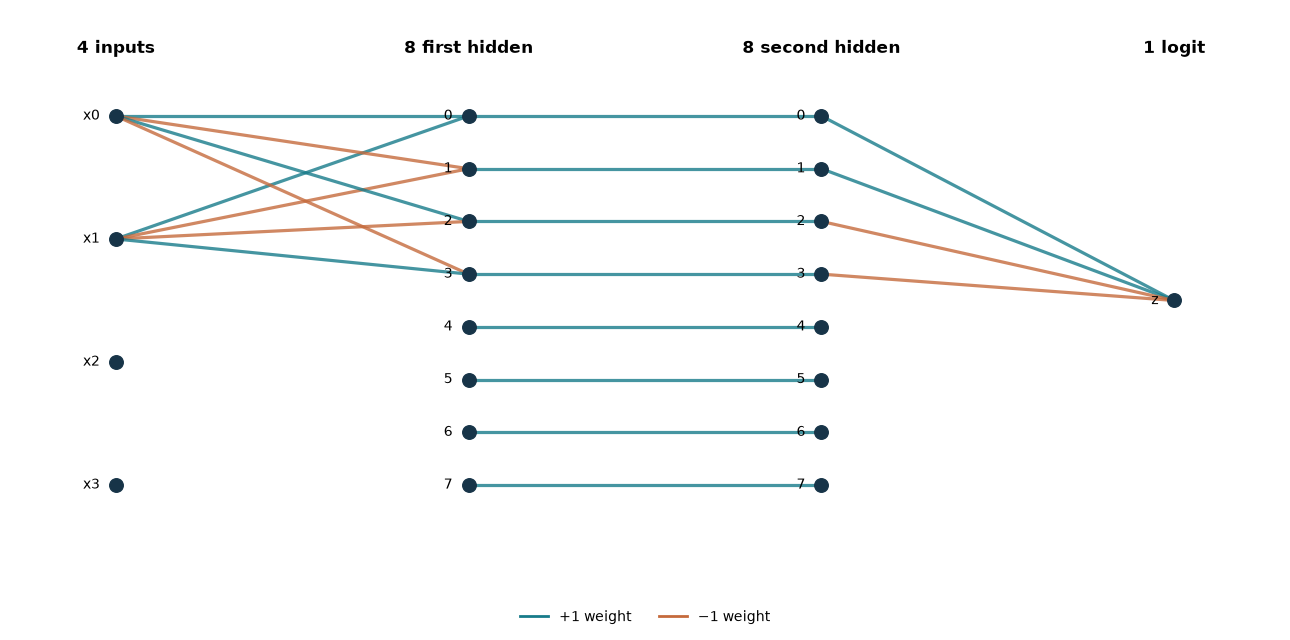

In [3]:
fig, ax = plt.subplots(figsize=(13, 6.5))
ys = [np.linspace(.12,.88,n)[::-1] if n > 1 else np.array([.5]) for n in (4,8,8,1)]
xs = [0, 1, 2, 3]
for layer, name in enumerate(('W1','W2','W3')):
    matrix = w[name]
    for dest in range(matrix.shape[0]):
        for source in range(matrix.shape[1]):
            value = float(matrix[dest,source])
            if value:
                ax.plot([xs[layer],xs[layer+1]], [ys[layer][source],ys[layer+1][dest]],
                        color='#177b8a' if value > 0 else '#c56a3c', lw=2.3, alpha=.8, zorder=1)
for layer in range(4):
    ax.scatter([xs[layer]]*len(ys[layer]),ys[layer],s=95,c='#173448',zorder=3)
    for i,y in enumerate(ys[layer]):
        ax.text(xs[layer]-.045,y,(['x0','x1','x2','x3'][i] if layer==0 else ('z' if layer==3 else str(i))),
                ha='right',va='center',fontsize=10)
for x,label in zip(xs,['4 inputs','8 first hidden','8 second hidden','1 logit']):
    ax.text(x,1.01,label,ha='center',fontsize=12,fontweight='bold')
ax.plot([],[],color='#177b8a',lw=2,label='+1 weight')
ax.plot([],[],color='#c56a3c',lw=2,label='−1 weight')
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.01),ncol=2)
ax.set(xlim=(-.3,3.3),ylim=(-.10,1.10));ax.axis('off');fig.tight_layout();plt.show()

## 3. The calculation, step by step

The first four `W1` rows compute **ReLU(x0 + x1)**, **ReLU(−x0 − x1)**, **ReLU(x0 − x1)**, and **ReLU(−x0 + x1)**. The second layer passes them through because its weights form an identity matrix and these values are nonnegative. The output adds the first pair and subtracts the second pair.

Since `ReLU(a) + ReLU(−a) = |a|`, the returned network computes:

**logit = |x0 + x1| − |x0 − x1|**

In exact arithmetic, this is positive for equal nonzero signs, negative for opposite signs, and zero on either axis. The threshold `logit > 0` therefore gives the specified class. This derivation explains the returned weights; it does not prove numerical behavior at every possible floating-point input.

In [4]:
examples = torch.tensor([[.6,.3,0,0],[-.6,-.3,.7,-.9],[-.6,.3,0,0],[.6,-.3,0,0],[0,.5,0,0]], dtype=torch.float32)
with torch.no_grad():
    h1, h2, z = net.activations(examples)
expected = ((examples[:,0] * examples[:,1]) > 0).to(torch.int32)
table = pd.DataFrame({'x0': examples[:,0].numpy(), 'x1': examples[:,1].numpy(),
    'h1[0]': h1[:,0].numpy(), 'h1[1]': h1[:,1].numpy(),
    'h1[2]': h1[:,2].numpy(), 'h1[3]': h1[:,3].numpy(),
    'logit': z[:,0].numpy(), 'prediction': (z[:,0]>0).int().numpy(), 'target': expected.numpy()})
display(table.style.format({'x0':'{:.1f}', 'x1':'{:.1f}', 'h1[0]':'{:.2f}', 'h1[1]':'{:.2f}', 'h1[2]':'{:.2f}', 'h1[3]':'{:.2f}', 'logit':'{:.2f}'}))
with torch.no_grad():
    symbolic = (examples[:,0]+examples[:,1]).abs() - (examples[:,0]-examples[:,1]).abs()
    assert torch.allclose(z[:,0], symbolic, atol=1e-6)
print('The displayed logits match the symbolic expression within float32 tolerance.')

,x0,x1,h1[0],h1[1],h1[2],h1[3],logit,prediction,target
0,0.6,0.3,0.90,0.00,0.30,0.00,0.60,1,1
1,-0.6,-0.3,0.00,0.90,0.00,0.30,0.60,1,1
2,-0.6,0.3,0.00,0.30,0.00,0.90,-0.60,0,0
3,0.6,-0.3,0.30,0.00,0.90,0.00,-0.60,0,0
4,0.0,0.5,0.50,0.00,0.00,0.50,0.00,0,0


The displayed logits match the symbolic expression within float32 tolerance.


## 4. See the decision surface

The colors show the model's **logits**, not probabilities. The black lines mark `x0 = 0` and `x1 = 0`, where the specified class is 0. The nuisance inputs are fixed at zero for this visualization.

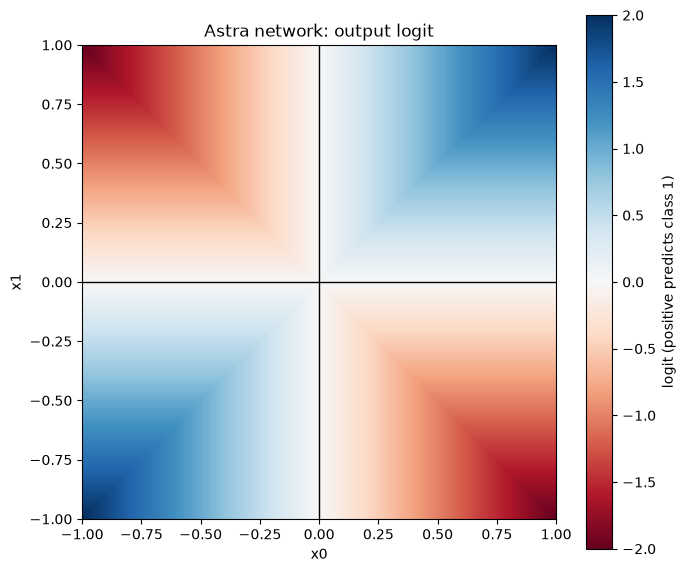

In [5]:
grid = np.linspace(-1,1,201,dtype=np.float32)
a, b = np.meshgrid(grid,grid)
points = torch.from_numpy(np.column_stack([a.ravel(),b.ravel(),np.zeros(a.size,np.float32),np.zeros(a.size,np.float32)]))
with torch.no_grad(): surface = net(points).numpy().reshape(a.shape)
fig,ax = plt.subplots(figsize=(7,6))
limit = float(np.max(np.abs(surface)))
im = ax.imshow(surface, origin='lower', extent=[-1,1,-1,1], cmap='RdBu', vmin=-limit, vmax=limit, aspect='equal')
ax.axhline(0,color='black',lw=1);ax.axvline(0,color='black',lw=1)
ax.set(xlabel='x0',ylabel='x1',title='Astra network: output logit')
fig.colorbar(im,ax=ax,label='logit (positive predicts class 1)')
fig.tight_layout();plt.show()

## 5. Check the held-out results

The frozen networks are scored on the **same 4,096 balanced examples** used earlier, with 1,024 examples in each sign quadrant. The other scores are recorded comparison results. The original network was trained; the earlier repair was restricted to one multiplicative edit; each from-scratch construction was allowed to specify every parameter. These are **different tasks**, so the ranking is descriptive rather than a controlled comparison of methods.

Astra from scratch: 4,096 / 4,096 correct (100.00%)


,Network,Accuracy,Correct,Errors
0,Astra from scratch,100.00%,4096,0
1,Qwen from scratch,100.00%,4096,0
2,Original trained,99.68%,4083,13
3,Best prior repair: Astra adaptive,96.29%,3944,152
4,Weakened network,92.33%,3782,314


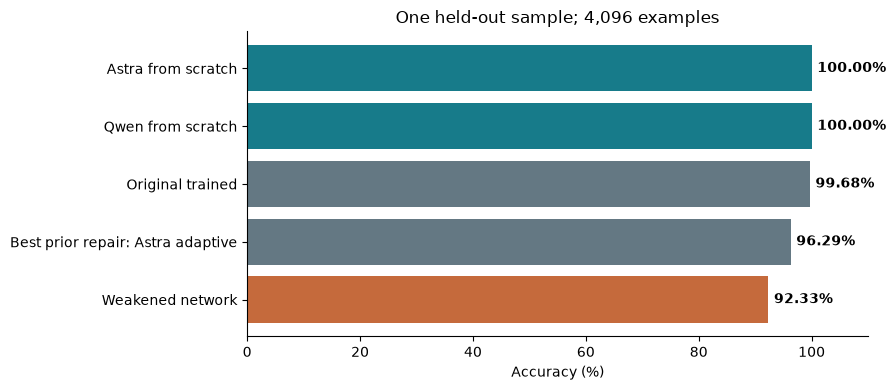

In [6]:
cfg = json.loads((ROOT / 'experiments/repair_v2.json').read_text())
x_test, y_test = make_split(**cfg['splits']['final_evaluation'])
with torch.no_grad():
    logits = net(x_test)
    assert torch.isfinite(logits).all()
    correct = (logits > 0) == y_test.bool()
count = int(correct.sum())
accuracy = float(correct.float().mean())
assert len(x_test) == 4096 and accuracy == results['accuracy']['accuracy']
print(f'Astra from scratch: {count:,} / {len(x_test):,} correct ({accuracy:.2%})')
qwen_results = json.loads((ROOT / 'results/qwen_from_scratch.json').read_text())
assert qwen_results['evaluation_split'] == cfg['splits']['final_evaluation']
comparison = pd.DataFrame([
    ('Astra from scratch', accuracy),
    ('Qwen from scratch', qwen_results['accuracy']['accuracy']),
    ('Original trained', results['original_trained']['accuracy']),
    ('Best prior repair: Astra adaptive', results['best_prior_repair']['accuracy']),
    ('Weakened network', results['weakened']['accuracy']),
], columns=['Network','Accuracy'])
comparison['Correct'] = (comparison['Accuracy'] * len(x_test)).round().astype(int)
comparison['Errors'] = len(x_test) - comparison['Correct']
display(comparison.style.format({'Accuracy':'{:.2%}'}))
fig,ax=plt.subplots(figsize=(9,4))
colors=['#177b8a','#177b8a','#647883','#647883','#c56a3c']
bars=ax.barh(comparison['Network'],100*comparison['Accuracy'],color=colors)
ax.invert_yaxis();ax.set(xlim=(0,110),xlabel='Accuracy (%)',title='One held-out sample; 4,096 examples')
for bar,v in zip(bars,comparison['Accuracy']):
    ax.text(100*v+1,bar.get_y()+bar.get_height()/2,f'{v:.2%}',va='center',fontweight='bold')
ax.spines[['top','right']].set_visible(False);fig.tight_layout();plt.show()

## 6. Inspect quadrant and boundary checks

A quadrant combines the signs of `x0` and `x1`; the nuisance variables vary in the held-out sample. The axis examples below are separate, illustrative spot checks because the balanced held-out generator avoids exact zeros. Passing these checks does not exhaust all numerical edge cases.

In [7]:
quadrants=[]
for name, sx, sy in [('Q++',1,1),('Q+-',1,-1),('Q-+',-1,1),('Q--',-1,-1)]:
    mask=(x_test[:,0]*sx>0)&(x_test[:,1]*sy>0)
    n=int(mask.sum()); good=int(correct[mask].sum())
    quadrants.append({'Quadrant':name,'Correct':good,'Total':n,'Accuracy':good/n})
display(pd.DataFrame(quadrants).style.format({'Accuracy':'{:.2%}'}))
axis=torch.tensor([[0.,.5,0.,0.],[.5,0.,0.,0.],[0.,-.5,0.,0.],[-.5,0.,0.,0.],[0.,0.,0.,0.]])
with torch.no_grad(): axis_z=net(axis)[:,0]
axis_table=pd.DataFrame({'x0':axis[:,0].numpy(),'x1':axis[:,1].numpy(),'logit':axis_z.numpy(),'predicted class':(axis_z>0).int().numpy(),'target class':0})
display(axis_table)
assert not (axis_z>0).any()

,Quadrant,Correct,Total,Accuracy
0,Q++,1024,1024,100.00%
1,Q+-,1024,1024,100.00%
2,Q-+,1024,1024,100.00%
3,Q--,1024,1024,100.00%


,x0,x1,logit,predicted class,target class
0,0.0,0.5,0.0,0,0
1,0.5,0.0,0.0,0,0
2,0.0,-0.5,0.0,0,0
3,-0.5,0.0,0.0,0,0
4,0.0,0.0,0.0,0,0


## 7. Qwen's independent construction

Qwen received the same prompt in a separate conversation. The provider reported an output-token overrun; its already-returned response was accepted within the reservation without a retry. Qwen expressed the single output bias as scalar `0`; we wrapped it in a one-element array **without changing its value**, recorded that format-only normalization, and froze the network before evaluation.

In [8]:
qwen_path = ROOT / 'private/from_scratch_qwen/frozen.json'
if not qwen_path.is_file():
    raise FileNotFoundError('The ignored frozen Qwen network is required to rerun this section.')
qwen_raw = qwen_path.read_bytes()
qwen_frozen = json.loads(qwen_raw)
assert hashlib.sha256(qwen_raw).hexdigest() == qwen_results['freeze_sha256']
q = {name: np.asarray(values,dtype=np.float32) for name,values in qwen_frozen['weights'].items()}
qnet=WeightReaderMLP()
qnet.load_state_dict({key:torch.from_numpy(q[name].copy()) for name,key in [('W1','fc1.weight'),('b1','fc1.bias'),('W2','fc2.weight'),('b2','fc2.bias'),('W3','fc3.weight'),('b3','fc3.bias')]})
qnet.eval()
print('Format normalization:', qwen_frozen['format_repairs'])
for name,row_names,col_names in [('W1',[f'h1[{i}]' for i in range(8)],['x0','x1','x2','x3']),('W2',[f'h2[{i}]' for i in range(8)],[f'h1[{i}]' for i in range(8)]),('W3',['logit'],[f'h2[{i}]' for i in range(8)])]:
    print(name); display(pd.DataFrame(q[name],index=row_names,columns=col_names).style.format('{:.0f}'))
print('Biases:',{name:q[name].tolist() for name in ('b1','b2','b3')})

Format normalization: ['Wrapped scalar output bias b3 in a one-element array']
W1


,x0,x1,x2,x3
h1[0],1,0,0,0
h1[1],-1,0,0,0
h1[2],1,-1,0,0
h1[3],-1,1,0,0
h1[4],0,0,0,0
h1[5],0,0,0,0
h1[6],0,0,0,0
h1[7],0,0,0,0


W2


,h1[0],h1[1],h1[2],h1[3],h1[4],h1[5],h1[6],h1[7]
h2[0],1,-1,-1,0,0,0,0,0
h2[1],-1,1,0,-1,0,0,0,0
h2[2],0,0,0,0,0,0,0,0
h2[3],0,0,0,0,0,0,0,0
h2[4],0,0,0,0,0,0,0,0
h2[5],0,0,0,0,0,0,0,0
h2[6],0,0,0,0,0,0,0,0
h2[7],0,0,0,0,0,0,0,0


W3


,h2[0],h2[1],h2[2],h2[3],h2[4],h2[5],h2[6],h2[7]
logit,1,1,0,0,0,0,0,0


Biases: {'b1': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'b2': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'b3': [0.0]}


### Qwen: nonzero connections

Teal lines are +1 and orange lines are −1, using the same layout as the Astra diagram.

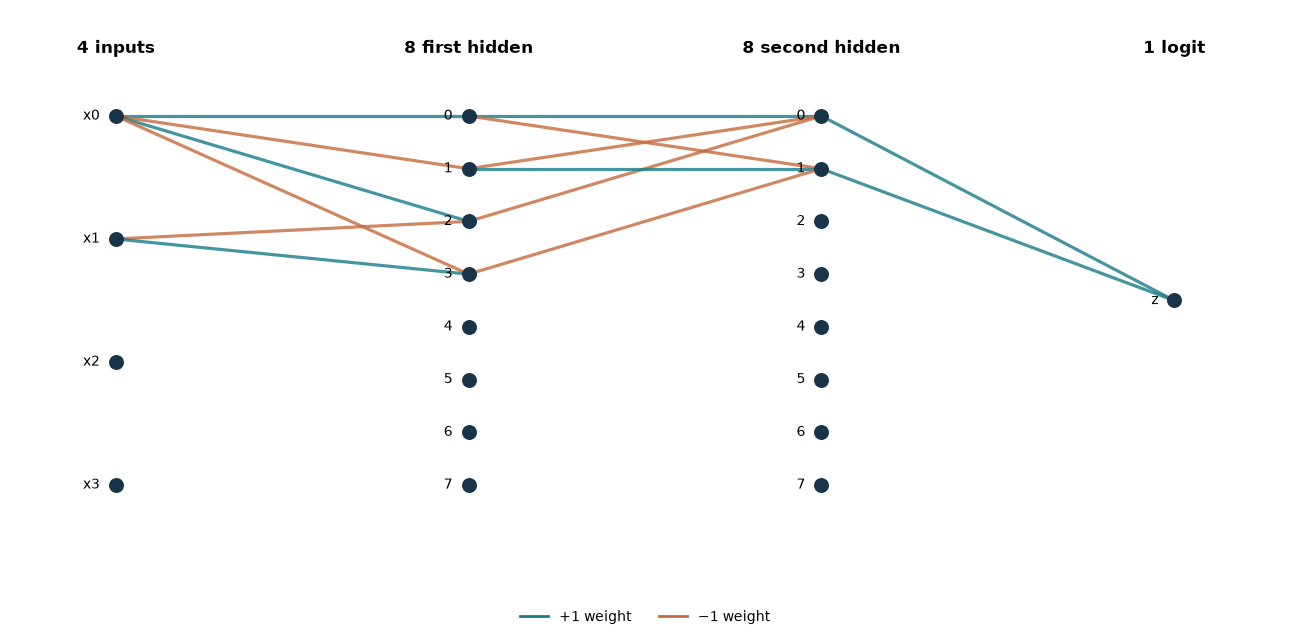

In [9]:
fig, ax = plt.subplots(figsize=(13, 6.5))
ys = [np.linspace(.12,.88,n)[::-1] if n > 1 else np.array([.5]) for n in (4,8,8,1)]
xs = [0, 1, 2, 3]
for layer, name in enumerate(('W1','W2','W3')):
    matrix = q[name]
    for dest in range(matrix.shape[0]):
        for source in range(matrix.shape[1]):
            value = float(matrix[dest,source])
            if value:
                ax.plot([xs[layer],xs[layer+1]], [ys[layer][source],ys[layer+1][dest]],
                        color='#177b8a' if value > 0 else '#c56a3c', lw=2.3, alpha=.8, zorder=1)
for layer in range(4):
    ax.scatter([xs[layer]]*len(ys[layer]),ys[layer],s=95,c='#173448',zorder=3)
    for i,y in enumerate(ys[layer]):
        ax.text(xs[layer]-.045,y,(['x0','x1','x2','x3'][i] if layer==0 else ('z' if layer==3 else str(i))),
                ha='right',va='center',fontsize=10)
for x,label in zip(xs,['4 inputs','8 first hidden','8 second hidden','1 logit']):
    ax.text(x,1.01,label,ha='center',fontsize=12,fontweight='bold')
ax.plot([],[],color='#177b8a',lw=2,label='+1 weight')
ax.plot([],[],color='#c56a3c',lw=2,label='−1 weight')
ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.01),ncol=2)
ax.set(xlim=(-.3,3.3),ylim=(-.10,1.10));ax.axis('off');fig.tight_layout();plt.show()

### How Qwen's circuit works

The first layer forms `ReLU(x0)`, `ReLU(−x0)`, `ReLU(x0−x1)`, and `ReLU(−x0+x1)`. The two active second-layer units compute `ReLU(min(x0, x1))` and `ReLU(min(−x0, −x1))`; the output adds them. Consequently its logit is **positive when the signs match and zero otherwise**. Zero predicts class 0, so this still implements the required rule.

Astra instead produces a *negative* logit for opposite signs. The two classifiers agree on these examples while exposing different raw values; these logits should not be interpreted as calibrated probabilities.

In [10]:
with torch.no_grad():
    qz=qnet(x_test)[:,0]
    qcorrect=(qz>0)==y_test[:,0].bool()
    assert torch.isfinite(qz).all() and int(qcorrect.sum())==4096
    expression=torch.relu(torch.minimum(x_test[:,0],x_test[:,1])) + torch.relu(torch.minimum(-x_test[:,0],-x_test[:,1]))
    assert torch.allclose(qz,expression,atol=1e-6)
    az=net(examples)[:,0]; q_example=qnet(examples)[:,0]
print(f'Qwen: {int(qcorrect.sum()):,} / {len(x_test):,} correct ({float(qcorrect.float().mean()):.2%})')
display(pd.DataFrame({'x0':examples[:,0].numpy(),'x1':examples[:,1].numpy(),'Astra logit':az.numpy(),'Qwen logit':q_example.numpy(),'target':expected.numpy()}))
qgroups=[]
for name,sx,sy in [('Q++',1,1),('Q+-',1,-1),('Q-+',-1,1),('Q--',-1,-1)]:
    mask=(x_test[:,0]*sx>0)&(x_test[:,1]*sy>0)
    qgroups.append({'Quadrant':name,'Correct':int(qcorrect[mask].sum()),'Total':int(mask.sum())})
display(pd.DataFrame(qgroups))
with torch.no_grad():
    q_axis=qnet(axis)[:,0]
assert not (q_axis>0).any()
print('All five exact-axis spot checks predict class 0.')

Qwen: 4,096 / 4,096 correct (100.00%)


,x0,x1,Astra logit,Qwen logit,target
0,0.6,0.3,0.6,0.3,1
1,-0.6,-0.3,0.6,0.3,1
2,-0.6,0.3,-0.6,0.0,0
3,0.6,-0.3,-0.6,0.0,0
4,0.0,0.5,0.0,0.0,0


,Quadrant,Correct,Total
0,Q++,1024,1024
1,Q+-,1024,1024
2,Q-+,1024,1024
3,Q--,1024,1024


All five exact-axis spot checks predict class 0.


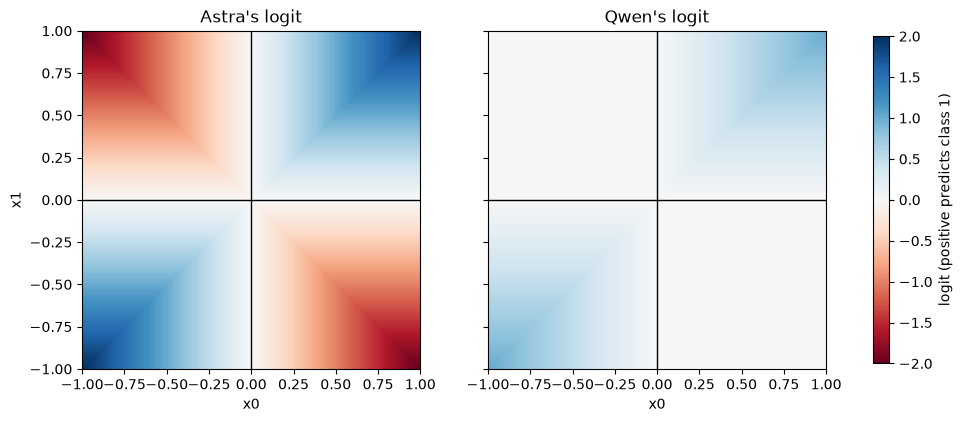

In [11]:
with torch.no_grad(): qsurface=qnet(points).numpy().reshape(a.shape)
fig,axes=plt.subplots(1,2,figsize=(12,5),sharex=True,sharey=True)
for ax,arr,title in zip(axes,[surface,qsurface],["Astra's logit", "Qwen's logit"]):
    im=ax.imshow(arr,origin='lower',extent=[-1,1,-1,1],cmap='RdBu',vmin=-2,vmax=2,aspect='equal')
    ax.axhline(0,color='black',lw=1);ax.axvline(0,color='black',lw=1);ax.set(title=title,xlabel='x0')
axes[0].set_ylabel('x1');fig.colorbar(im,ax=axes,label='logit (positive predicts class 1)',shrink=.85)
plt.show()

## What can we conclude?

- Both returned networks scored **100.00% (4,096/4,096)** on the reused held-out sample, with 100% in each quadrant.
- Astra's circuit computes `|x0+x1| − |x0−x1|`; Qwen's circuit computes a different logit using two ReLU-implemented minimum functions. They agree on the classification rule, though their logits differ.
- Neither network was trained or fine-tuned in this experiment, and neither reviewer received the earlier model's weights or probes. A related hand-set circuit already existed in this project, so the outcome does not establish a novel architecture.
- Each reviewer had one attempt on a simple, explicitly described task. The held-out set was previously analyzed; repeated attempts and fresh tests on additional tasks would give stronger evidence.

**Sources:** [Follow-up prompt](../prompts/FROM_SCRATCH.md), [study protocol](../PROTOCOL.md), [evaluation script](../scripts/from_scratch.py), and [earlier repair results notebook](11_harder_repair_results.ipynb). Raw responses, frozen weights, checkpoints, and generated JSON are ignored by Git; executed outputs remain visible in a fresh clone, but rerunning requires the local artifacts.